# Tutorial 2 · EP full text (EPAB), humanoid sector (query v0.2 draft)

EPAB is the full text database of the EPO, which we can use through the TIP platform. It contains the European patent (EP) publications of:
- type A (applications the EPO publishes)
- type B (documents which are granted patents)

EPAB is one table on Google BigQuery with one row per publication and nested fields. The EPAB client is the Python interface to that table.

This database only covers patents filed at the EPO, directly or through an international (PCT) application.

The EPAB database gives us more information on the European patents of the PATSTAT database: the full text of the claims and of the description, and the search report of the examiner.

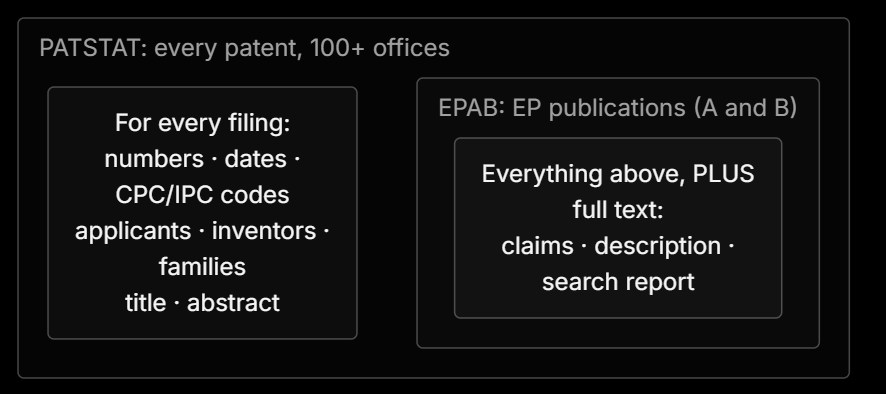

In this notebook we query EPAB for all publications that match our Step 0 rule, then check how many of them link to PATSTAT and read their claims and search reports.

We do this because PATSTAT only gives us titles and abstracts. EPAB adds two things that matter for the project. The claims say what is really protected, so they show whether a patent is about a humanoid robot or only mentions one. The search report gives the examiner's opinion on how close the invention is to earlier patents, which is a measure of novelty we can use in Step 4.

EPAB only covers the part of the sector that was filed at the EPO, so we use it to look closer at patents, not to measure the size of the sector.

In [1]:
import re
import sys
from pathlib import Path
from pprint import pprint
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd

from epo.tipdata.epab import EPABClient
from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS202_APPLN_TITLE, TLS203_APPLN_ABSTR, TLS224_APPLN_CPC

In this cell, we define all the choices that affect the results in one place, so changing one setting changes the whole notebook:

In [2]:
ENV = 'PROD'                      # TEST to check that the code runs; PROD only for the final numbers

# ---------------------------------------------------------------- the sector rule
# The rule is written once, in config/sector_rule.yaml, and read here through src/sector_rule.py.
sys.path.insert(0, str(Path('src').resolve()))
from sector_rule import SectorQueries, load_rule, rule_constants

RULE = load_rule()
(CORE_CPC, ROBOT_CPC, EXCLUDE_CPC, PROSTHESIS_CPC, EXCLUDE_PROSTHESES, STRONG_KW, MEDIUM_KW,
 ADJACENT_KW, EXCLUDE_KW, TRUTH_CPC, QUERY_VERSION, YEAR_MIN, YEAR_MAX, IPR_TYPE) = rule_constants(RULE)

# ---------------------------------------------------------------- paths
OUTPUT_DIR = Path('outputs/t2_epab')      # ignored by git: the files stay on TIP
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
STEP0_IDS = Path('outputs/step0/sector_family_ids.csv')

# ---------------------------------------------------------------- EP full text (EPAB)
TEXT_PARTS = ('title', 'abstract')          # where the keywords are searched, as in the PATSTAT rule (section 3.3 tries adding the claims)
LANGUAGE = 'EN'                             # EPAB also holds German and French text: see the limits in section 7
PUBLICATION_DATES = f'{YEAR_MIN}0101-{YEAR_MAX}1231'    # publication dates, not priority years: a close but not identical window
MAX_DOWNLOAD = 2000                         # sector publications whose text is downloaded (section 5)
BASELINE_DOWNLOAD = 3000                    # robot-code publications downloaded for the search-report comparison (section 6)
CLAIMS_ONLY_TERMS = ['anthropomorphic robot', 'humanoid']   # words checked in section 3.2
INCLUDE_DESCRIPTION = False                 # the description is tens of pages per publication: leave it out unless needed
COUNT_DESCRIPTION = False                   # also count term hits in the description (slow on PROD)
pd.set_option('display.max_colwidth', 120)

We load the PATSTAT and the EPAB clients:

In [3]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

epab = EPABClient(env=ENV)      # every EPAB query starts from this object

In [4]:
# The sector as PATSTAT queries, built from the rule (src/sector_rule.py).
Q = SectorQueries(db, SimpleNamespace(APPLN=TLS201_APPLN, TITLE=TLS202_APPLN_TITLE,
                                      ABSTR=TLS203_APPLN_ABSTR, CPC=TLS224_APPLN_CPC), RULE)
window_filters = Q.window_filters
sector_query = Q.sector_query
SECTOR = Q.sector_subquery()          # one column, fid: the sector's families, computed in the database


def scope(q):
    # keep only sector families; the join runs in the database, so no family IDs travel to Python
    return Q.scope(q, SECTOR)

In [5]:
sector_ids_db = patstat.df(sector_query()).fid.tolist()
print(f'sector families ({ENV}, {QUERY_VERSION}): {len(sector_ids_db)}')
if STEP0_IDS.exists():
    step0_ids = set(pd.read_csv(STEP0_IDS)['docdb_family_id'])
    print('same families as the Step 0 list:', step0_ids == set(sector_ids_db))
    print('(the Step 0 list was saved on TEST; a PROD run will differ, which is expected)')
else:
    print('Step 0 list not found at', STEP0_IDS, '- put this notebook next to the Step 0 outputs folder')

sector families (PROD, v0.2 draft): 8268
Step 0 list not found at outputs/step0/sector_family_ids.csv - put this notebook next to the Step 0 outputs folder


**What the PROD run shows.** The PATSTAT sector has 8,268 families with the v0.2 rule. A day earlier it had 7,522 with the same rule, so TIP loaded new data in between: numbers from before this run are not directly comparable.

## 1. Helpers

These small functions are used everywhere below. The most important one counts the publications of a query inside the database, so we never download more than we need. The others clean the text that EPAB returns: it keeps XML tags in the claims, and a text can come as a string, a list or one entry per language.

In [6]:
def drop_total_row(stats):
    "get_stats appends a total row (df.loc['Total'] = df.sum(...)): drop it, or every count is added twice."
    numeric = stats.select_dtypes('number')
    if len(stats) > 1 and (numeric.iloc[-1] == numeric.iloc[:-1].sum()).all():
        return stats.iloc[:-1]
    return stats


def safe_stats(query, field):
    "get_stats without its total row, or an empty table if the query matches nothing (the library then raises 'cannot set a frame with no defined columns')."
    try:
        return drop_total_row(query.get_stats(field))
    except ValueError:
        if len(query.get_results('publication.number', output_type='list', limit=1)) == 0:
            return pd.DataFrame()          # really empty: not an error
        raise                              # the query has results, so this is a different problem


def n_publications(query):
    "Number of publications of a query, counted by the database. Nothing is downloaded."
    stats = safe_stats(query, 'publication.kind')         # one value per publication, so the counts add up
    if len(stats) == 0:
        return 0
    column = 'unique_publications' if 'unique_publications' in stats.columns else 'count'
    return int(stats[column].sum())


def strip_tags(text):
    "Remove the XML tags and collapse the spaces."
    return re.sub(r'\s+', ' ', re.sub(r'<[^>]+>', ' ', str(text))).strip()


def text_in(value, language='EN', keep_tags=False):
    "The text of a full-text field in one language, whatever its structure (dict by language, dict with text, list)."
    clean = (lambda t: str(t)) if keep_tags else strip_tags
    if isinstance(value, list):
        parts = [v for v in value if isinstance(v, dict) and str(v.get('language', language)).upper() == language] or value
        return ' '.join(text_in(v, language, keep_tags) for v in parts)
    if isinstance(value, dict):
        if 'text' in value:
            return clean(value['text'])
        key = language.lower() if language.lower() in value else next(iter(value), None)
        return text_in(value[key], language, keep_tags) if key else ''
    return clean(value) if value else ''


def dig(record, path):
    "record['a']['b'] for the path 'a.b'; None if a step is missing."
    for key in path.split('.'):
        if not isinstance(record, dict):
            return None
        record = record.get(key)
    return record


def as_list(value):
    "A repeated EPAB field as a list (it can come back as None, one dict or a list)."
    if value is None:
        return []
    return value if isinstance(value, list) else [value]


def shorten(value, max_chars=300):
    if isinstance(value, str):
        return value if len(value) <= max_chars else value[:max_chars] + f' ... [{len(value):,} characters]'
    if isinstance(value, dict):
        return {k: shorten(v, max_chars) for k, v in value.items()}
    if isinstance(value, list):
        return [shorten(v, max_chars) for v in value]
    return value


def publication_numbers(query, limit=MAX_DOWNLOAD * 5):
    "Publication numbers of an EPAB query (an empty set if it matches nothing)."
    if n_publications(query) == 0:
        return set()
    return {dig(r, 'publication.number') for r in query.get_results('publication.number', output_type='list', limit=limit)}

## 2. The fields

EPAB is one big table. Before we query it, we read the list of its fields, so we use the right names in the cells below. If a field has another name on TIP, we see it here instead of getting a confusing error later. This cell is the same as in the tutorial.

In [7]:
project, dataset, table = epab.full_table_name.split('.')
schema_sql = f'''
    SELECT field_path, data_type, description
    FROM `{project}.{dataset}.INFORMATION_SCHEMA.COLUMN_FIELD_PATHS`
    WHERE table_name = '{table}'
'''


def fields_from_widget(fields, prefix=''):
    "Fallback: walk the field tree shown by epab.fields()."
    rows = []
    for f in fields:
        path = prefix + f['name']
        rows.append({'field_path': path, 'data_type': f.get('type'), 'description': f.get('description')})
        rows += fields_from_widget(f.get('fields', []), path + '.')
    return rows


try:
    schema = pd.DataFrame(epab.sql_query(schema_sql))
except Exception:
    schema = pd.DataFrame(fields_from_widget(epab.fields().input_data['']))

schema['super field'] = schema['field_path'].str.split('.').str[0]
print(f"{len(schema)} fields in {schema['super field'].nunique()} super fields")
print('super fields:', ', '.join(dict.fromkeys(schema['super field'])))


def find_fields(pattern):
    "Fields whose path matches the regular expression (case-insensitive)."
    return schema[schema['field_path'].str.contains(pattern, case=False, regex=True)]['field_path'].tolist()


for label, pattern in [('applicant', r'applicant'), ('inventor', r'inventor'), ('search report / citations', r'search|citation'),
                       ('classification', r'cpc|ipc')]:
    print(f'{label}:', find_fields(pattern)[:12])

111 fields in 23 super fields
super fields: epab_doc_id, publication, application, pct, designated_states, priority, parent, divisional, applicant, inventor, representative, ipc, cpc, csets, prior_art, reference, search_report, srep_citation, title, abstract, description, claims, attachment
applicant: ['applicant', 'applicant.name', 'applicant.address', 'applicant.city', 'applicant.country']
inventor: ['inventor', 'inventor.name', 'inventor.address', 'inventor.city', 'inventor.country']
search report / citations: ['search_report', 'search_report.date', 'search_report.ipc_field', 'search_report.is_no_unity', 'search_report.is_incomplete_search', 'search_report.is_no_search', 'srep_citation', 'srep_citation.is_patent', 'srep_citation.document', 'srep_citation.document_xml', 'srep_citation.category', 'srep_citation.relevant_claims']
classification: ['ipc', 'ipc.version', 'ipc.symbol', 'ipc.category', 'ipc.edition', 'ipc.text', 'cpc', 'cpc.symbol', 'cpc.category', 'cpc.edition', 'cpc.text'

## 3. The Step 0 rule as an EPAB query

We write our Step 0 rule again, this time as an EPAB query, so we find the same kind of patents in the EPO full text. The rule has three ways in:

- A: the CPC code for walking robots and a strong humanoid word;
- B: a robot code and a medium word (for example *gait* or *dexterous hand*);
- C: a strong humanoid word alone.

Patents with an exclusion code or word (toys, exoskeletons, four-legged robots...) are removed.

One thing to know when reading the table: every patent of layer A is also in layer C, because both need a strong word. So layer A does not add patents to the sector. It only marks the patents we are most sure about. The last row shows what the walking-robot code would add on its own, without any keyword. The team has to decide whether that code alone is enough (see the Step 0 notes).

In [8]:
TEXT_METHODS = {'title': epab.query_title, 'abstract': epab.query_abstract,
                'claims': epab.query_claims, 'description': epab.query_description}


def any_of(pieces):
    "OR of query objects."
    pieces = list(pieces)
    query = pieces[0]
    for piece in pieces[1:]:
        query = query | piece
    return query


def cpc_query(prefixes):
    return any_of(epab.query_cpc(symbol=p + '%') for p in prefixes)


def text_query(terms, parts=TEXT_PARTS):
    "Publications whose text parts contain at least one of the terms (terms joined by commas mean OR)."
    return any_of(TEXT_METHODS[part](', '.join(terms), language=LANGUAGE) for part in parts)


base = epab.query_publication(number='%', kind_code='%', date=PUBLICATION_DATES)

core, robot = cpc_query(CORE_CPC), cpc_query(ROBOT_CPC)
strong, medium, adjacent_kw = text_query(STRONG_KW), text_query(MEDIUM_KW), text_query(ADJACENT_KW)
excluded = cpc_query(EXCLUDE_CPC) | text_query(EXCLUDE_KW)
if EXCLUDE_PROSTHESES:
    excluded = excluded | cpc_query(PROSTHESIS_CPC)
out = excluded | (adjacent_kw - strong)            # exclusions and the adjacent group

layer_A = (core & strong) - out
layer_B = (robot & medium) - out
layer_C = strong - out
sector_epab = (layer_A | layer_B | layer_C) & base

layer_counts = pd.DataFrame([
    {'query': 'all EP publications in the window', 'publications': n_publications(base)},
    {'query': 'core code B62D57/032', 'publications': n_publications(core & base)},
    {'query': 'robot codes (B25J, B62D57, G06N3/008)', 'publications': n_publications(robot & base)},
    {'query': 'strong keywords', 'publications': n_publications(strong & base)},
    {'query': 'medium keywords', 'publications': n_publications(medium & base)},
    {'query': 'layer A (after exclusions)', 'publications': n_publications(layer_A & base)},
    {'query': 'layer B (after exclusions)', 'publications': n_publications(layer_B & base)},
    {'query': 'layer C (after exclusions)', 'publications': n_publications(layer_C & base)},
    {'query': 'removed by exclusions or the adjacent group', 'publications': n_publications(out & (strong | medium | core) & base)},
    {'query': 'SECTOR (A or B or C)', 'publications': n_publications(sector_epab)},
    # not in the sector: what the walking-robot code would add if the team decided the code alone is enough
    {'query': 'core code without any rule keyword, after exclusions (NOT in the sector)',
     'publications': n_publications((core & base) - (strong | medium) - out)},
])
layer_counts.to_csv(OUTPUT_DIR / 'epab_layer_counts.csv', index=False)
display(layer_counts)

,query,publications
0,all EP publications in the window,6164281
1,core code B62D57/032,143
2,"robot codes (B25J, B62D57, G06N3/008)",8409
3,strong keywords,240
4,medium keywords,1212
5,layer A (after exclusions),5
6,layer B (after exclusions),93
7,layer C (after exclusions),226
8,removed by exclusions or the adjacent group,109
9,SECTOR (A or B or C),317


**What the PROD run shows.** Out of 6.2 million EP publications in the window, 317 are in our sector.

| Layer | Publications |
|---|---|
| A: walking-robot code and a strong word | 5 |
| B: robot code and a medium word | 93 |
| C: a strong word | 226 |
| removed by the exclusions | 109 |

The walking-robot code and the humanoid words rarely meet: only 5 publications have both. Layer A adds nothing on its own, because every A publication is also in C.

The last row shows that the walking-robot code alone, without any of our words, would add 83 publications (+26%). Before taking them in, we should read some: many are probably four-legged or other walking machines.

### 3.1 Where the vocabulary appears

For each strong word, we count the publications that contain it in the title, the abstract and the claims. This tells us where the humanoid words really are. A word that is often in the claims but rarely in the title is probably not the subject of the patent, and searching the claims could bring in patents that only mention it.

In [9]:
parts_to_count = ['title', 'abstract', 'claims'] + (['description'] if COUNT_DESCRIPTION else [])
rows = []
for term in STRONG_KW:
    row = {'term': term}
    for part in parts_to_count:
        row[part] = n_publications(TEXT_METHODS[part](term, language=LANGUAGE) & base)
    rows.append(row)
where = pd.DataFrame(rows).set_index('term')
where.to_csv(OUTPUT_DIR / 'epab_where_terms_appear.csv')
display(where)

,title,abstract,claims
term,,,
humanoid,98,45,205
biped,73,65,140
two-legged robot,1,1,3
android robot,0,0,1
anthropomorphic robot,2,17,200
human-like robot,0,0,1


**What the PROD run shows.** "Humanoid" and "biped" are the words that matter: each is in the title of 70 to 100 publications. "Two-legged robot", "android robot" and "human-like robot" are almost never used, so they add little to the rule.

"Anthropomorphic robot" behaves differently: it is in the title of only 2 publications but in the claims of 200. Section 3.2 checks why.

In [10]:
# Control: common words must return hits. If they return 0 too, the way we call the text methods is wrong,
# and a 0 for 'humanoid' means nothing. If only the humanoid words are 0, the database simply has none.
controls = pd.DataFrame([{'term': t, **{part: n_publications(TEXT_METHODS[part](t, language=LANGUAGE) & base)
                                         for part in ('title', 'abstract')}}
                         for t in ('robot', 'gripper', 'walking')]).set_index('term')
display(controls)

,title,abstract
term,,
robot,20260,10347
gripper,2252,1550
walking,1094,1160


**What the PROD run shows.** Common words return thousands of publications ("robot" is in 20,260 titles), so the text search works. The small numbers above are real, not an error.

### 3.2 Is "anthropomorphic robot" a humanoid word?

"Anthropomorphic robot" is in the claims of about 200 publications, but in the title of only 2. We suspect that patent lawyers use it for ordinary industrial robot arms ("the robot is an anthropomorphic robot with six axes"). If that is true, the word should not be a strong word of our rule.

To check, we take the publications that have the word in their claims but not in their title or abstract, and look at their CPC codes and titles. If most of them are in B25J 9 (industrial manipulators) and the titles talk about arms, grippers or tools, the word is boilerplate. We do the same for "humanoid" as a comparison.

In [11]:
def cpc_main_groups(record):
    "The CPC main groups of a publication, e.g. 'B25J9' for B25J 9/1612."
    symbols = [c.get('symbol') if isinstance(c, dict) else c for c in as_list(record.get('cpc'))]
    return {re.sub(r'\s', '', str(s)).split('/')[0] for s in symbols if s}


sector_numbers = publication_numbers(sector_epab)
claims_only_rows = []
for term in CLAIMS_ONLY_TERMS:
    # in the claims, and not in the title or the abstract
    claims_only = (TEXT_METHODS['claims'](term, language=LANGUAGE) & base) - text_query([term], ('title', 'abstract'))
    n = n_publications(claims_only)
    print(f'\n"{term}": {n} publications have it in the claims but not in the title or abstract')
    if n == 0:
        continue
    found = claims_only.get_results('publication.number, title, cpc', output_type='list', limit=300)
    groups = pd.Series([g for r in found for g in cpc_main_groups(r)]).value_counts() / len(found)
    print(f'share of them already in our EPAB sector: {sum(dig(r, "publication.number") in sector_numbers for r in found) / len(found):.0%}')
    print('CPC main groups (share of these publications that carry each group):')
    display(groups.head(10).round(2).to_frame('share'))
    print('first titles:')
    for r in found[:8]:
        print('  -', text_in(r.get('title'), LANGUAGE)[:110])
    claims_only_rows.append({'term': term, 'claims only': n,
                             'share in B25J9 (industrial manipulators)': round(groups.get('B25J9', 0), 3),
                             'share in B62D57 (legged)': round(groups.get('B62D57', 0), 3)})
if claims_only_rows:
    pd.DataFrame(claims_only_rows).to_csv(OUTPUT_DIR / 'epab_claims_only_terms.csv', index=False)


"anthropomorphic robot": 185 publications have it in the claims but not in the title or abstract
share of them already in our EPAB sector: 2%
CPC main groups (share of these publications that carry each group):


,share
B25J9,0.05
B25J15,0.05
B24B27,0.04
B25J11,0.04
B65B5,0.04
B29D30,0.04
B29D2030,0.04
B65B57,0.03
B25J21,0.03
B24B49,0.03


first titles:
  - Method and apparatus for applying paint on basically flat parts
  - A MACHINE AND A METHOD FOR PRODUCING SANITARY ARTICLES
  - A PACKAGING MACHINE FOR PACKING GROUPS OF PRODUCTS IN PACKAGING BOXES FORMED STARTING FROM FLAT TUBULAR DIE-CU
  - METHOD AND APPARATUS FOR REALIZING A CONTINUOUS AND ORDERED FLOW OF CONTAINERS
  - PROCESS AND APPARATUS FOR BUILDING TYRES FOR VEHICLE WHEELS
  - Method and apparatus for rapidly filling trays with individual products
  - PROGRAMMABLE STATION AND PLANT FOR THE PRODUCTION OF PLATES WITH CHROMATIC EFFECTS
  - AN UNWINDING ASSEMBLY AND METHOD FOR AUTOMATICALLY LOADING REELS INTO AN UNWINDING ASSEMBLY

"humanoid": 138 publications have it in the claims but not in the title or abstract
share of them already in our EPAB sector: 8%
CPC main groups (share of these publications that carry each group):


,share
G06F3,0.08
G06V40,0.06
G06N3,0.06
G06V20,0.05
G06T19,0.04
B25J19,0.04
B25J13,0.04
B25J9,0.04
G06N20,0.04
G06V10,0.03


first titles:
  - INTERACTIVE PRINTED MATERIAL AND SENSOR APPARATUS
  - Anthropomorphic phantom for medical imaging systems
  - APPARATUS AND METHODS FOR CONTENT DESCRIPTION
  - SPHERICAL JOINT AND ROBOT JOINT STRUCTURE COMPRISING SAME
  - MAGNETIC SPRING
  - WIRELESS INTERACTIVE HEADSET
  - MODULAR ADD-ON AUGMENTED REALITY HEAD-UP DISPLAY, INTERFACES AND CONTROLS
  - AUTOMATED CLINICAL DOCUMENTATION SYSTEM AND METHOD


**What the PROD run shows.** "Anthropomorphic robot" is not a humanoid word. 185 publications have it in their claims but not in the title or abstract, and only 2% of them are in our sector. Their titles are packaging machines, paint sprayers, tyre building and tray filling: patent lawyers use "anthropomorphic robot" for an ordinary industrial arm. We should remove it from the strong words of the rule.

"Humanoid" in the claims only (138 publications) is also mostly noise: headsets, augmented-reality displays, clinical documentation, a medical "anthropomorphic phantom". Only 8% are in our sector. So the claims mention humanoids far more often than they are really about them.

### 3.3 What changes if the claims are searched too

Here we count the publications with a strong word when we search the title only, the title and the abstract (our rule), and the claims too. Searching the claims finds many more publications. The table cannot say whether those extra publications belong to the sector: section 3.2 and the hand labelling of Step 0 do that.

In [12]:
variants = {
    'title': ('title',),
    'title + abstract (the rule)': ('title', 'abstract'),
    'title + abstract + claims': ('title', 'abstract', 'claims'),
}
if COUNT_DESCRIPTION:
    variants['title + abstract + claims + description'] = ('title', 'abstract', 'claims', 'description')
parts_table = pd.DataFrame([{'text parts searched': name, 'publications with a strong word': n_publications(text_query(STRONG_KW, parts) & base)}
                            for name, parts in variants.items()])
parts_table['added vs the rule'] = parts_table['publications with a strong word'] - int(
    parts_table.loc[parts_table['text parts searched'].str.contains('the rule'), 'publications with a strong word'].iloc[0])
display(parts_table)

,text parts searched,publications with a strong word,added vs the rule
0,title,169,-71
1,title + abstract (the rule),240,0
2,title + abstract + claims,637,397


**What the PROD run shows.** Searching the claims too would almost triple the publications with a strong word (637 instead of 240). Section 3.2 shows that most of these extra publications are not about humanoid robots. We keep the rule as it is: title and abstract only.

### 3.4 The sector year by year

We count the sector's A1 publications per year. An A1 is the first publication of an application, with the search report, so it is about one per invention filed at the EPO. This series only covers the EPO, so it should rise and fall like the PATSTAT counts of Step 1 but not match them.

We also count all A1 publications in EPAB for each year. If a year is low for the whole database too, the dip comes from the data, not from the humanoid sector.

years with a sector count of 0: [2014, 2020]
years that look incomplete in the whole database: none


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
sector A1,2.00,1.00,3.00,11.00,13.0,3.00,7.00,4.00,2.00,4.00,...,6.00,11.00,5.00,5.00,0.0,5.0,24.00,15.00,20.00,32.00
all A1 in EPAB,65071.00,65084.00,63534.00,60651.00,76629.0,76142.00,83520.00,85227.00,84114.00,82169.00,...,134850.00,142164.00,151697.00,158832.00,166656.0,165285.0,173408.00,173291.00,164235.00,161346.00
"sector per 10,000 A1",0.31,0.15,0.47,1.81,1.7,0.39,0.84,0.47,0.24,0.49,...,0.44,0.77,0.33,0.31,0.0,0.3,1.38,0.87,1.22,1.98


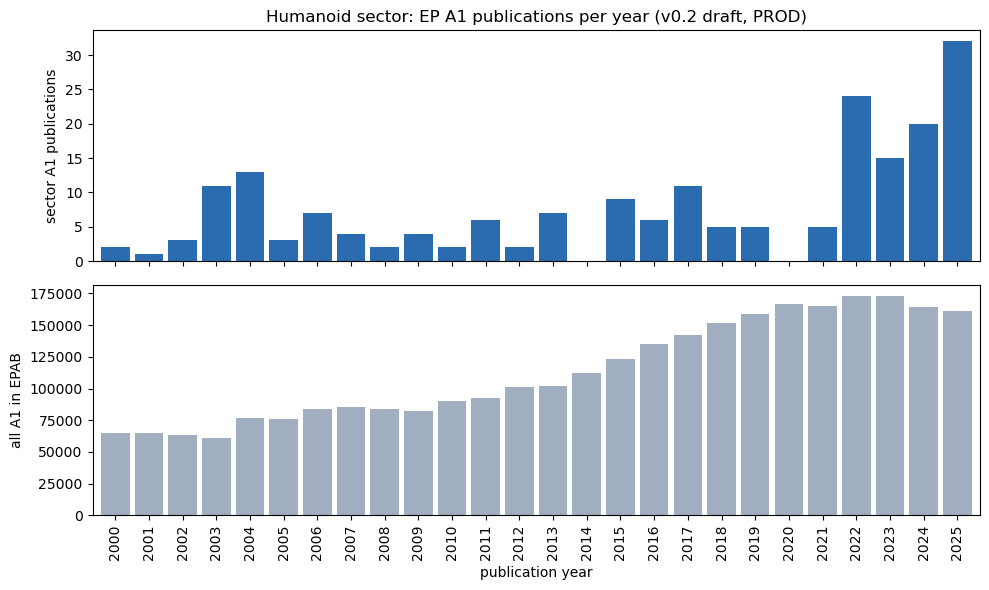

In [13]:
sector_a1 = sector_epab & epab.query_publication_kind_code('A1')
year_rows = []
for year in range(YEAR_MIN, YEAR_MAX + 1):
    in_year = epab.query_publication(number='%', kind_code='A1', date=f'{year}0101-{year}1231')
    year_rows.append({'year': year, 'sector A1': n_publications(sector_a1 & in_year), 'all A1 in EPAB': n_publications(in_year)})
a1_years = pd.DataFrame(year_rows).set_index('year')
a1_years['sector per 10,000 A1'] = (a1_years['sector A1'] / a1_years['all A1 in EPAB'].where(a1_years['all A1 in EPAB'] > 0) * 10_000).round(2)
a1_years.to_csv(OUTPUT_DIR / 'epab_a1_per_year.csv')

# A year where the whole database has less than half its usual number of A1 publications is probably incomplete.
usual = a1_years['all A1 in EPAB'].rolling(5, center=True, min_periods=3).median()
odd_years = a1_years.index[a1_years['all A1 in EPAB'] < 0.5 * usual].tolist()
print('years with a sector count of 0:', a1_years.index[a1_years['sector A1'] == 0].tolist())
print('years that look incomplete in the whole database:', odd_years or 'none')
display(a1_years.T)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1_years['sector A1'].plot.bar(ax=axes[0], color='#2b6cb0', width=0.85)
axes[0].set(ylabel='sector A1 publications', title=f'Humanoid sector: EP A1 publications per year ({QUERY_VERSION}, {ENV})')
a1_years['all A1 in EPAB'].plot.bar(ax=axes[1], color='#a0aec0', width=0.85)
axes[1].set(ylabel='all A1 in EPAB', xlabel='publication year')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'epab_figure1_a1_per_year.png', dpi=150)
plt.show()

**What the PROD run shows.** The sector is small at the EPO: about 1 to 13 A1 publications a year until 2021. Then it jumps to 24, 15, 20 and 32 in 2022-2025.

The EPO also grows, so we compare with all EPAB A1 publications. Per 10,000 A1, the sector goes from about 0.3 to 0.8 in 2016-2021 to 1.4, 0.9, 1.2 and 2.0 in 2022-2025: two to four times more. Humanoid filings in Europe really took off in the last four years. 2003-2004 had a first, smaller peak (1.8 and 1.7 per 10,000).

2014 and 2020 have no sector publication, but the whole database is complete in those years. With only about 5 publications a year at that time, a zero year can happen by chance.

## 4. Linking EPAB to PATSTAT

We want to know whether EPAB and PATSTAT find the same European patents for our sector, and we need a link between the two to use EPAB data later. On the PATSTAT side we take the sector families that have an EP application. On the EPAB side we take the sector publications. We then match their application numbers.

The two databases write application numbers differently, so the cell prints a few of each. We keep the digits and the first 8 of them. Check on the samples that this makes the numbers comparable before trusting the overlap.

In [14]:
ep_apps = patstat.df(
    scope(db.query(TLS201_APPLN.docdb_family_id.label('fid'), TLS201_APPLN.appln_nr.label('appln_nr'))
          .filter(TLS201_APPLN.appln_auth == 'EP', *window_filters())).distinct())
if ep_apps.empty:   # on TIP an empty result comes back with no columns at all
    ep_apps = pd.DataFrame({'fid': pd.Series(dtype='int64'), 'appln_nr': pd.Series(dtype='object')})
n_ep_families = ep_apps.fid.nunique()

if n_publications(sector_epab) == 0:
    print('The EPAB sector is empty (expected on TEST): there are no application numbers to compare.')
    sector_apps_epab = []
else:
    sector_apps_epab = sector_epab.get_results('application.number', output_type='list', limit=MAX_DOWNLOAD * 5)
epab_numbers = [dig(r, 'application.number') for r in sector_apps_epab]
epab_numbers = [n for n in epab_numbers if n]

print(f'PATSTAT: {len(sector_ids_db):,} sector families, {n_ep_families:,} of them with an EP application ({ep_apps.appln_nr.nunique():,} EP application numbers)')
print(f'EPAB: {len(set(epab_numbers)):,} distinct application numbers among the sector publications')
print('samples, PATSTAT appln_nr  :', ep_apps.appln_nr.head(5).tolist())
print('samples, EPAB application.number:', list(dict.fromkeys(epab_numbers))[:5])


def key(number):
    "Digits only, first 8: a guess at the common part of the two formats. CHECK it against the samples above."
    return re.sub(r'\D', '', str(number))[:8]


patstat_keys, epab_keys = {key(n) for n in ep_apps.appln_nr}, {key(n) for n in epab_numbers}
both = patstat_keys & epab_keys
link_table = pd.DataFrame([
    {'set': 'PATSTAT sector EP applications', 'numbers': len(patstat_keys)},
    {'set': 'EPAB sector applications', 'numbers': len(epab_keys)},
    {'set': 'in both', 'numbers': len(both)},
])
link_table['share of PATSTAT'] = (link_table.numbers / max(len(patstat_keys), 1)).round(3)
display(link_table)

PATSTAT: 8,268 sector families, 511 of them with an EP application (597 EP application numbers)
EPAB: 229 distinct application numbers among the sector publications
samples, PATSTAT appln_nr  : ['09753975', '03250735', '11181358', '02760670', '07791469']
samples, EPAB application.number: ['13172585.5', '20899736.1', '21425060.7', '22206610.2', '22864206.2']


,set,numbers,share of PATSTAT
0,PATSTAT sector EP applications,597,1.000
1,EPAB sector applications,229,0.384
2,in both,202,0.338


**What the PROD run shows.** Only 511 of the 8,268 PATSTAT families (6%) have an EP application. Most humanoid patents are never filed at the EPO, so EPAB shows a small part of the sector.

The link between the two databases works: 202 of the 229 EPAB applications (88%) are also in the PATSTAT sector. The other way, only 34% of the PATSTAT EP applications are found by the EPAB rule, because EPAB searches English text by publication date, and PATSTAT by priority year and in more text.

**How to read the table.** If "in both" is close to zero while both sets are large, the matching is wrong: change `key` after reading the samples. If it is large, the two rules agree. Numbers found only in PATSTAT are patents the EPAB version of the rule misses (other text parts, other language, other dates). Numbers found only in EPAB are patents the PATSTAT rule misses. Both are worth a look in the Step 0 labelling.

## 5. The claims of the sector

We download the sector's A1 publications with their claims and search reports, and describe the claims: how many there are, how long the first one is, and whether a humanoid word appears in them.

This matters because the claims are what is legally protected. A patent with "humanoid" in the abstract but not in any claim protects something more general, for example a gripper that could also go on a humanoid. Such a patent is less central to the sector.

Some publications have no English claims, because they were filed in German or French. We leave them out of the shares, otherwise they would look like patents without a humanoid word. We also split the results by layer (A, B, C), because layer B does not need a strong word at all.

In [15]:
fields = 'publication.number, publication.kind, publication.date, application.number, title, abstract, claims, search_report, srep_citation'
if INCLUDE_DESCRIPTION:
    fields += ', description'
n_sector_a1 = n_publications(sector_a1)
if n_sector_a1 == 0:
    records = []
    print('The EPAB sector has no A1 publications (expected on TEST): nothing to download.')
else:
    records = sector_a1.get_results(fields, output_type='list', limit=MAX_DOWNLOAD)
    print(f'{len(records):,} of {n_sector_a1:,} sector A1 publications downloaded (limit {MAX_DOWNLOAD:,})')


def claim_texts(value):
    "The claims as a list of strings: by <claim> tags if present, otherwise by claim numbers."
    raw = text_in(value, LANGUAGE, keep_tags=True)
    parts = re.findall(r'<claim[ >].*?</claim>', raw, flags=re.S)
    if not parts:
        parts = [p for p in re.split(r'(?:(?<=\s)|^)(?=\d{1,3}\s*\.\s+[A-Z])', raw) if p.strip()]
    return [strip_tags(p) for p in parts]


def is_independent(claim):
    "A claim that does not refer to another claim ('according to claim 1', 'of claim 3'). A heuristic."
    return not re.search(r'\bclaims?\s+\d+', claim, flags=re.I)


def report_summary(record):
    "The search report of one publication: number of cited documents and how many carry X, Y and A."
    citations = [c for c in as_list(record.get('srep_citation')) if isinstance(c, dict)]
    letters = [set(re.findall(r'[A-Z]', str(c.get('category') or ''))) for c in citations]
    return {'citations': len(citations), 'labels': sum(len(l) for l in letters),
            'X': sum('X' in l for l in letters), 'Y': sum('Y' in l for l in letters), 'A': sum('A' in l for l in letters)}


# the link to PATSTAT (section 4): application number -> DOCDB family
fid_by_key = dict(zip(ep_apps.appln_nr.map(key), ep_apps.fid))
in_A = publication_numbers(layer_A & sector_a1)
in_B = publication_numbers(layer_B & sector_a1)

rows = []
for rec in records:
    claims = claim_texts(rec.get('claims'))
    first = claims[0] if claims else ''
    number = dig(rec, 'publication.number')
    rows.append({
        'publication': number, 'date': dig(rec, 'publication.date'),
        'application_key': key(dig(rec, 'application.number')),
        'layer': 'A' if number in in_A else ('B' if number in in_B else 'C'),     # A first, then B, then C
        'abstract_words': len(text_in(rec.get('abstract'), LANGUAGE).split()),
        'has_english_claims': len(claims) > 0, 'claims': len(claims),
        'independent_claims': sum(is_independent(c) for c in claims), 'claim1_words': len(first.split()),
        'claim1_has_strong_word': any(t in first.lower() for t in STRONG_KW),
        'claims_have_strong_word': any(t in ' '.join(claims).lower() for t in STRONG_KW),
        **report_summary(rec),
    })
TEXT_COLUMNS = ['publication', 'date', 'application_key', 'layer', 'abstract_words', 'has_english_claims', 'claims',
                'independent_claims', 'claim1_words', 'claim1_has_strong_word', 'claims_have_strong_word',
                'citations', 'labels', 'X', 'Y', 'A']
texts = pd.DataFrame(rows, columns=TEXT_COLUMNS)          # the columns exist even when there are no rows
texts['docdb_family_id'] = texts['application_key'].map(fid_by_key)   # empty when the family is not in the PATSTAT sector
texts['has_text_report'] = texts['citations'] > 0

if len(texts):
    english = texts[texts.has_english_claims]
    print(f'{len(texts) - len(english)} of {len(texts)} publications have no English claims (German or French): left out of the shares below')
    print(f'claim 1 longer than 1,000 words (the split into claims probably failed): {(english.claim1_words > 1000).sum()}')
    by_layer = english.groupby('layer').agg(
        publications=('publication', 'count'), median_claims=('claims', 'median'),
        median_independent_claims=('independent_claims', 'median'), median_claim1_words=('claim1_words', 'median'),
        share_strong_word_claim1=('claim1_has_strong_word', 'mean'),
        share_strong_word_claims=('claims_have_strong_word', 'mean'),
    ).round(3)
    by_layer.loc['all'] = [len(english), english.claims.median(), english.independent_claims.median(), english.claim1_words.median(),
                           round(english.claim1_has_strong_word.mean(), 3), round(english.claims_have_strong_word.mean(), 3)]
    by_layer.to_csv(OUTPUT_DIR / 'epab_sector_claims_by_layer.csv')
    display(by_layer)
    # one row per sector A1 publication, with its PATSTAT family: the table the next steps can join on docdb_family_id
    texts.to_csv(OUTPUT_DIR / 'epab_sector_publications.csv', index=False)
    print(f'{texts.docdb_family_id.notna().sum()} of {len(texts)} publications linked to a PATSTAT sector family')
else:
    print('No publications: claim statistics skipped.')

199 of 199 sector A1 publications downloaded (limit 2,000)
7 of 199 publications have no English claims (German or French): left out of the shares below
claim 1 longer than 1,000 words (the split into claims probably failed): 15


,publications,median_claims,median_independent_claims,median_claim1_words,share_strong_word_claim1,share_strong_word_claims
layer,,,,,,
A,3.0,15.0,2.0,108.0,0.667,1.000
B,68.0,15.0,2.0,146.5,0.015,0.029
C,121.0,9.0,1.0,220.0,0.529,0.595
all,192.0,11.0,2.0,183.0,0.349,0.401


177 of 199 publications linked to a PATSTAT sector family


**What the PROD run shows.** We downloaded the 199 sector A1 publications. 7 have no English claims, and for 15 the claims were not split correctly (claim 1 is longer than 1,000 words), so those counts are a little off.

| Layer | Publications | Humanoid word in claim 1 | Humanoid word in any claim |
|---|---|---|---|
| A | 3 | 67% | 100% |
| B | 68 | 1.5% | 3% |
| C | 121 | 53% | 60% |

In layer C, about 40% of the publications mention a humanoid in the title or abstract but do not claim one. The humanoid is the setting, not what is protected. Layer B almost never claims a humanoid: these patents enter through words like "robot hand" or "gait", and many may be ordinary robot parts. 177 of the 199 publications are linked to a PATSTAT family, so these numbers can be used in the next steps.

**How to read the table.** In layers A and C the patents were selected because a humanoid word is in the title or abstract. The share with a humanoid word in claim 1 tells us how often that word is also what is protected. In layer B no humanoid word was needed, so a low share there is expected and does not mean the patents are wrong. For the Step 0 labelling, the patents of layers A and C without a humanoid word in their claims are the ones to read first.

## 6. The search report: how close is the prior art?

When the EPO publishes an application (A1), it adds a search report. The examiner lists the earlier documents closest to the invention and gives each one a letter. X means the document alone already questions the novelty of the claims. Y means it does so combined with another document. A means it is only background.

Many X and Y letters mean the invention is close to what already exists. Few mean it is more new. We compare the humanoid sector with all robot-code publications, the same benchmark as in Step 1. We use two measures: the share of the letters that are X or Y, and the share of search reports with at least one X or Y. The second one counts each patent once, so it is the more reliable of the two. Reports before mid-2012 are images in EPAB, so only reports with text are counted.

For Step 4 this is useful: a patent whose search report has no X or Y is new in the examiner's opinion.

In [16]:
def wilson(successes, n, z=1.96):
    "95% confidence interval of a share (Wilson). It shows how much a share could move by chance with this many patents."
    if n == 0:
        return (float('nan'), float('nan'))
    p = successes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / (1 + z * z / n)
    return (round(centre - half, 3), round(centre + half, 3))


def report_table(summaries):
    "Search-report measures of a group of publications."
    df = pd.DataFrame(summaries, columns=['citations', 'labels', 'X', 'Y', 'A'])
    reports = df[df.citations > 0]
    labels = max(int(reports['labels'].sum()), 1)
    with_xy = int(((reports.X + reports.Y) > 0).sum())
    return {'publications': len(df), 'with a text search report': len(reports),
            'cited documents per report (mean)': round(reports.citations.mean(), 2) if len(reports) else float('nan'),
            'share of letters that are X': round(reports.X.sum() / labels, 3),
            'share of letters that are Y': round(reports.Y.sum() / labels, 3),
            'share of letters that are A': round(reports.A.sum() / labels, 3),
            'share of reports with an X': round((reports.X > 0).mean(), 3) if len(reports) else float('nan'),
            'share of reports with an X or Y': round(with_xy / len(reports), 3) if len(reports) else float('nan'),
            '95% interval (X or Y)': wilson(with_xy, len(reports))}


robot_a1 = robot & base & epab.query_publication_kind_code('A1')
n_robot_a1 = n_publications(robot_a1)
robot_records = (robot_a1.get_results('publication.number, search_report, srep_citation', output_type='list', limit=BASELINE_DOWNLOAD)
                 if n_robot_a1 else [])
print(f'robot-code A1 publications: {n_robot_a1:,}; downloaded for the comparison: {len(robot_records):,}'
      + ('' if len(robot_records) >= n_robot_a1 else ' (the first ones returned, not a random sample)'))

if len(texts) or robot_records:
    search_reports = pd.DataFrame({
        'humanoid sector': report_table(texts[['citations', 'labels', 'X', 'Y', 'A']].to_dict('records')),
        'all robot-code A1': report_table([report_summary(r) for r in robot_records]),
    })
    search_reports.to_csv(OUTPUT_DIR / 'epab_search_report_comparison.csv')
    display(search_reports)
else:
    print('No A1 publications in either group (expected on TEST): table skipped.')

robot-code A1 publications: 4,868; downloaded for the comparison: 3,000 (the first ones returned, not a random sample)


,humanoid sector,all robot-code A1
publications,199,3000
with a text search report,43,1009
cited documents per report (mean),4.67,4.18
share of letters that are X,0.262,0.299
share of letters that are Y,0.153,0.189
share of letters that are A,0.55,0.485
share of reports with an X,0.721,0.732
share of reports with an X or Y,0.814,0.831
95% interval (X or Y),"(0.674, 0.903)","(0.806, 0.852)"


**What the PROD run shows.** The humanoid sector and robotics in general look the same in the search reports:

| | Humanoid sector | All robot codes |
|---|---|---|
| reports with an X | 72% | 73% |
| reports with an X or Y | 81% (67% to 90%) | 83% (81% to 85%) |
| letters that are A (background) | 55% | 49% |

So examiners find close earlier patents for humanoid inventions as often as for other robots. The humanoid sector is not more novel in the examiner's opinion.

Only 43 of the 199 sector publications have a text search report, so the sector numbers are uncertain: the range in brackets is wide. The robot benchmark uses the first 3,000 of 4,868 publications, not a random sample. For Step 4, the examiner's opinion covers too few patents to be used alone.

In [17]:
# One real search report, to see what the data looks like (the first sector publication that has a text report).
example = next((r for r in records if as_list(r.get('srep_citation'))), None)
if example is None:
    print('No sector publication with a text search report.')
else:
    citations = [{k: c.get(k) for k in ('category', 'document', 'relevant_claims') if isinstance(c, dict)}
                 for c in as_list(example.get('srep_citation'))[:4]]
    pprint(shorten({'publication': dig(example, 'publication.number'), 'search_report': example.get('search_report'),
                    'first cited documents': citations}, 200), width=120, sort_dicts=False)

{'publication': '4610152',
 'search_report': {'date': '20240803',
                   'ipc_field': ['B62D'],
                   'is_no_unity': False,
                   'is_incomplete_search': False,
                   'is_no_search': False},
 'first cited documents': [{'category': 'XA',
                            'document': 'US 9833903 B1 KUFFNER JAMES JOSEPH [US] 20171205',
                            'relevant_claims': '151-14'},
                           {'category': 'XA',
                            'document': 'CN 113129729 A UNIV SHANTOU 20210716',
                            'relevant_claims': '151-4,12-14'},
                           {'category': 'XA',
                            'document': 'US 2015041227 A1 JUN BONG-HUAN [KR] ET AL 20150212',
                            'relevant_claims': '151,6,7,9,11'}]}


**What the PROD run shows.** A real report, from 2024: the examiner cites three earlier patents, marked X (they alone question the novelty of some claims), including a US patent from 2017 and a Chinese university patent from 2021.

## 7. Limits to state in the appendix

- **Coverage.** EPAB only holds patents filed at the EPO, directly or through a PCT application. US, Chinese, Japanese and Korean patents that never came to the EPO are missing, and the humanoid sector is mostly Asian. So we use EPAB to look closer at patents (claims, search reports), not to measure the size or the geography of the sector.
- **Language.** We search English text. German and French publications are missed unless their title, which is always published in the three languages, has the word.
- **Dates.** EPAB gives publication dates, not priority years. An A1 comes about 18 months after the first filing.
- **Search reports** are text only from mid-2012. Earlier ones are images and count as "no report".
- **Matching.** Words are matched in the EPAB text index. Our words are English and specific, but we read the first hits by hand (section 3.2).

In [18]:
size = epab.sql_query(f'''
    SELECT COUNT(*) AS publications, COUNT(DISTINCT application.number) AS applications
    FROM `{epab.full_table_name}`
''')[0]
print(f"{epab.full_table_name}: {size['publications']:,} publications of {size['applications']:,} applications ({ENV})")

checks = {
    'the window count does not exceed the size of the table (fails if counts are added twice)': n_publications(base) <= size['publications'],
    'the sector is a subset of the window': n_publications(sector_epab) <= n_publications(base),
    'layer A is a subset of layer C (it needs a strong word too)': n_publications(layer_A & layer_C & base) == n_publications(layer_A & base),
    'sector A1 counts by year add up to the A1 total': int(a1_years['sector A1'].sum()) == n_publications(sector_a1 & epab.query_publication(number='%', kind_code='A1', date=PUBLICATION_DATES)),
    'the downloaded sample does not exceed the sector': len(records) <= n_publications(sector_a1),
    'every downloaded publication has a layer': texts['layer'].isin(['A', 'B', 'C']).all(),
}
for name, ok in checks.items():
    print('OK   -' if ok else 'CHECK -', name)

print('\nFiles for the next steps (in outputs/t2_epab/, they stay on TIP):')
for name, use in [('epab_sector_publications.csv', 'one row per sector A1: layer, claims, search-report letters, docdb_family_id (Step 4: examiner novelty)'),
                  ('epab_search_report_comparison.csv', 'sector vs robot benchmark (Step 1 / Step 4)'),
                  ('epab_claims_only_terms.csv', 'is "anthropomorphic robot" a humanoid word? (Step 0)'),
                  ('epab_layer_counts.csv', 'the rule on EPAB, including the core code alone (Step 0)'),
                  ('epab_a1_per_year.csv', 'EPO-only series per year, with the whole-database control')]:
    print(f'  {name:38} {use}')

p-epo-tip-prj-3a1f.p_epo_tip_euwe4_bqd_epab.publications: 8,172,086 publications of 5,017,243 applications (PROD)
OK   - the window count does not exceed the size of the table (fails if counts are added twice)
OK   - the sector is a subset of the window
OK   - layer A is a subset of layer C (it needs a strong word too)
OK   - sector A1 counts by year add up to the A1 total
OK   - the downloaded sample does not exceed the sector
OK   - every downloaded publication has a layer

Files for the next steps (in outputs/t2_epab/, they stay on TIP):
  epab_sector_publications.csv           one row per sector A1: layer, claims, search-report letters, docdb_family_id (Step 4: examiner novelty)
  epab_search_report_comparison.csv      sector vs robot benchmark (Step 1 / Step 4)
  epab_claims_only_terms.csv             is "anthropomorphic robot" a humanoid word? (Step 0)
  epab_layer_counts.csv                  the rule on EPAB, including the core code alone (Step 0)
  epab_a1_per_year.csv         

**What the PROD run shows.** All checks pass: the counts are not doubled, the sector and the layers fit inside each other, the yearly counts add up, and nothing more than the sector was downloaded.

## What we take from this notebook

1. **EPAB only sees a small part of the sector.** Only 6% of the families are filed at the EPO, so we use EPAB to look closer at patents, not to measure the sector.
2. **"Anthropomorphic robot" should leave the rule.** In claims it means an industrial arm, not a humanoid.
3. **We keep searching the title and abstract only.** Searching the claims would triple the hits, mostly with patents that only mention a humanoid.
4. **Many sector patents do not claim a humanoid.** About 40% of layer C, and almost all of layer B. The humanoid is often the setting, not what is protected, which matters for the hand labelling of Step 0.
5. **Humanoid filings at the EPO took off after 2021**, two to four times more than before, even after taking the growth of the EPO into account.
6. **The examiner's search reports show no difference** between the humanoid sector and robotics in general, and they cover too few patents to be a Step 4 ingredient on their own.